# Streaming decision tree on Housing.csv

This notebook streams the Housing data through a pipeline in chunks of 25 houses. It uses `numcompute` (the group package, here `io.read_csv`), `numcompute_stream` (my Assignment 2 package) and matplotlib, nothing else.

**Task:** predict whether a house costs at least the median price (545 houses, 12 features, some values missing).

**Test, then train:** each chunk first tests the current model and only then trains it, so every chunk is unseen data when it is scored.

# Imports

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "Dataset").is_dir():          # opened from demo/, so go up to the repository root
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from numcompute.io import read_csv
from numcompute_stream.metrics import (StreamingConfusionMatrix, StreamingF1,
                                       StreamingPrecision, StreamingRecall)
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import OneHotEncoder, SimpleImputer, StandardScaler
from numcompute_stream.stream import StreamTrainer, iter_chunks
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (compare_models, plot_metric_over_time,
                                         plot_predictions_vs_ground_truth)

print("Repository root:", ROOT)

Repository root: d:\Uni\COMP5004\A2


# Read CSV with io.py

In [2]:
DATA_PATH = ROOT / "Dataset" / "Housing.csv"
NUMERIC = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]
FLAGS = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]

numbers, _ = read_csv(DATA_PATH, usecols=NUMERIC)                                # floats, blank cell -> NaN
text, _ = read_csv(DATA_PATH, usecols=FLAGS + ["furnishingstatus"], dtype=str)   # strings, blank cell -> ""

print("number columns:", numbers.shape, "  text columns:", text.shape)
print("missing numbers per column:", dict(zip(NUMERIC, np.isnan(numbers).sum(axis=0).tolist())))
print("odd yes/no cells (blank or NAN):", int((~np.isin(np.char.lower(text[:, :6]), ["yes", "no"])).sum()))

number columns: (545, 6)   text columns: (545, 7)
missing numbers per column: {'price': 0, 'area': 1, 'bedrooms': 3, 'bathrooms': 2, 'stories': 1, 'parking': 3}
odd yes/no cells (blank or NAN): 10


# Features and Label

In [3]:
price = numbers[:, 0]
y = (price >= np.median(price)).astype(int)                 # 1 = a house at or above the median price

cleaned = np.char.lower(np.char.strip(text[:, :len(FLAGS)]))
flags = np.where(cleaned == "yes", 1.0, np.where(cleaned == "no", 0.0, np.nan))   # anything else is missing

furnishing_order = np.array(["unfurnished", "semi-furnished", "furnished"])
furnishing = (text[:, -1][:, None] == furnishing_order[None, :]).argmax(axis=1).astype(float)

X = np.hstack([numbers[:, 1:], flags, furnishing[:, None]])
feature_names = NUMERIC[1:] + FLAGS + ["furnishingstatus"]

print("X:", X.shape, " y:", y.shape, " share of class 1:", round(float(y.mean()), 3))
print("cells still missing in X:", int(np.isnan(X).sum()), "in", int(np.isnan(X).any(axis=1).sum()), "rows")

X: (545, 12)  y: (545,)  share of class 1: 0.505
cells still missing in X: 20 in 18 rows


# Cut data into stream

In [4]:
CHUNK_SIZE = 25
chunks = list(iter_chunks(X, y, CHUNK_SIZE, shuffle=True, random_state=0))
print(len(chunks), "chunks;", "sizes:", sorted({len(c[1]) for c in chunks}))
print("class 1 share per chunk:", np.round([c[1].mean() for c in chunks[:8]], 2), "...")

22 chunks; sizes: [20, 25]
class 1 share per chunk: [0.56 0.44 0.48 0.48 0.64 0.6  0.76 0.36] ...


# Preprocessing learns chunk by chunk

In [5]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
for i, (Xc, _) in enumerate(chunks[:4]):
    imputer.partial_fit(Xc)
    scaler.partial_fit(imputer.transform(Xc))
    print(f"after chunk {i}: median area = {imputer.statistics_[0]:8.1f}   mean area = {scaler.mean_[0]:8.1f}   "
          f"std area = {scaler.scale_[0]:7.1f}   rows seen = {scaler.n_samples_seen_[0]}")

after chunk 0: median area =   6100.0   mean area =   6259.6   std area =  2289.0   rows seen = 25
after chunk 1: median area =   5942.5   mean area =   5876.3   std area =  2209.6   rows seen = 50
after chunk 2: median area =   5450.0   mean area =   5591.6   std area =  2145.1   rows seen = 75
after chunk 3: median area =   4980.0   mean area =   5493.7   std area =  2065.8   rows seen = 100


# The encoder's output grows

In [6]:
encoder = OneHotEncoder()
for start in range(0, 200, 40):
    block = text[start:start + 40, :1]                       # the mainroad column, in file order
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        encoder.partial_fit(block)
    print(f"rows {start:3d}-{start + 39:3d}: {encoder.n_features_out_} output columns", "".join(f"\n    warning: {w.message}" for w in caught))
print("categories found:", encoder.categories_[0].tolist())

rows   0- 39: 2 output columns 
rows  40- 79: 2 output columns 
rows  80-119: 2 output columns 
rows 120-159: 3 output columns 
rows 160-199: 3 output columns 
categories found: ['', 'no', 'yes']


# the pipeline inside a StreamTrainer

In [7]:
def make_trainer(buffer_size):
    """A fresh pipeline (impute, scale, tree) inside a StreamTrainer."""
    pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size)),
    ])
    metrics = {
        "precision": StreamingPrecision(),
        "recall": StreamingRecall(),
        "f1": StreamingF1(),
        "confusion": StreamingConfusionMatrix(labels=[0, 1]),
    }
    return StreamTrainer(pipeline, metrics=metrics, window=100)

trainer = make_trainer(buffer_size=100)
print(trainer)

StreamTrainer(model=Pipeline, metrics=['precision', 'recall', 'f1', 'confusion'], window=100)


# train chunk by chunk, log every chunk

In [8]:
print("chunk  scored  chunk_acc  cumulative_acc  retrained  n_retrains  memory_bytes")
for Xc, yc in chunks:
    row = trainer.process_chunk(Xc, yc)          # test on the chunk first, then partial_fit on it
    print(f"{row['chunk']:5d}  {str(row['scored']):6}  {row['chunk_accuracy']:9.3f}  {row['cumulative_accuracy']:14.3f}  "
          f"{str(row['retrained']):9}  {row['n_retrains']:10d}  {row['memory_bytes']:12d}")

chunk  scored  chunk_acc  cumulative_acc  retrained  n_retrains  memory_bytes
    0  False         nan             nan  False               0          3272
    1  False         nan             nan  False               0          5872
    2  False         nan             nan  False               0          8472
    3  False         nan             nan  True                1          2597
    4  True        0.760           0.760  False               1          5197
    5  True        0.800           0.780  False               1          7797
    6  True        0.800           0.787  False               1         10397
    7  True        0.920           0.820  True                2          2009
    8  True        0.560           0.768  False               2          4609
    9  True        0.760           0.767  False               2          7209
   10  True        0.760           0.766  False               2          9809
   11  True        0.760           0.765  True                3 

# Final scores

In [9]:
matrix, labels = trainer.metrics["confusion"].result()
print("accuracy  :", round(trainer.accuracy_.result(), 3), f"(on {trainer.accuracy_.n_samples_} scored samples)")
print("precision :", round(trainer.metrics["precision"].result(), 3))
print("recall    :", round(trainer.metrics["recall"].result(), 3))
print("f1        :", round(trainer.metrics["f1"].result(), 3))
print("confusion matrix (rows = true class, columns = predicted class), labels", labels.tolist())
print(matrix)
print("retrains:", trainer.log_[-1]["n_retrains"], "  samples trained on:", trainer.n_seen_)

accuracy  : 0.739 (on 445 scored samples)
precision : 0.735
recall    : 0.761
f1        : 0.748
confusion matrix (rows = true class, columns = predicted class), labels [0, 1]
[[157  62]
 [ 54 172]]
retrains: 5   samples trained on: 545


# Accuracy over time, two plots

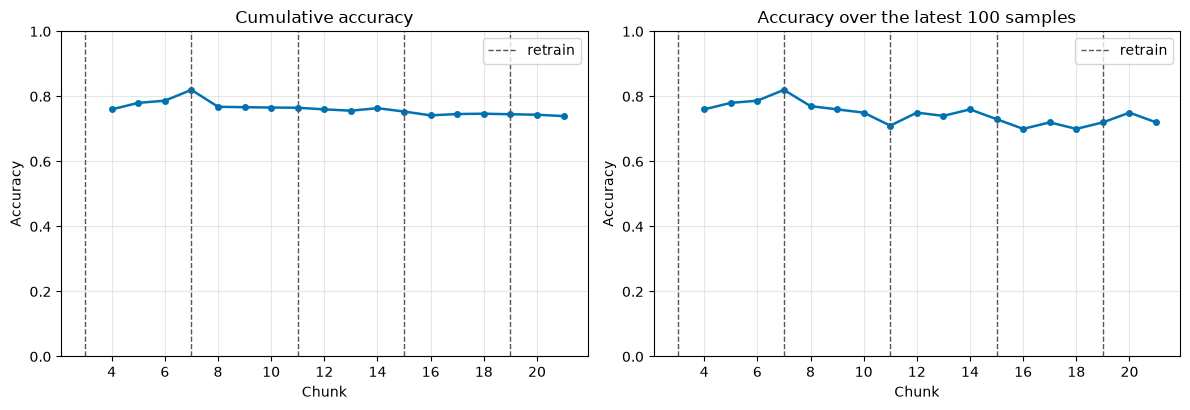

In [10]:
retrain_chunks = np.flatnonzero(trainer.history("retrained"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_metric_over_time(trainer.history("cumulative_accuracy"), "Cumulative accuracy", "Accuracy",
                      retrains=retrain_chunks, ylim=(0, 1), ax=axes[0])
plot_metric_over_time(trainer.history("rolling_accuracy"), "Accuracy over the latest 100 samples", "Accuracy",
                      retrains=retrain_chunks, ylim=(0, 1), ax=axes[1])
fig.tight_layout()
plt.show()

# Compare two buffer sizes

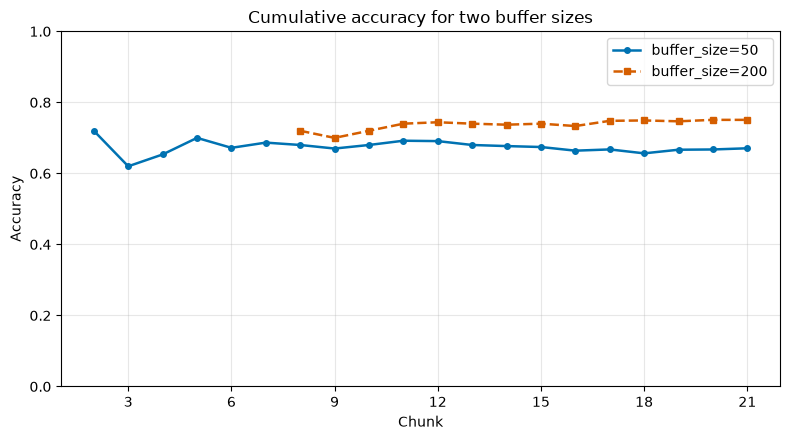

In [11]:
small, large = make_trainer(buffer_size=50), make_trainer(buffer_size=200)
for Xc, yc in chunks:
    small.process_chunk(Xc, yc)
    large.process_chunk(Xc, yc)

fig = compare_models(small.history("cumulative_accuracy"), large.history("cumulative_accuracy"),
                     labels=("buffer_size=50", "buffer_size=200"),
                     title="Cumulative accuracy for two buffer sizes", ylabel="Accuracy", ylim=(0, 1))
plt.show()

# Predictions against the truth on the last chunk

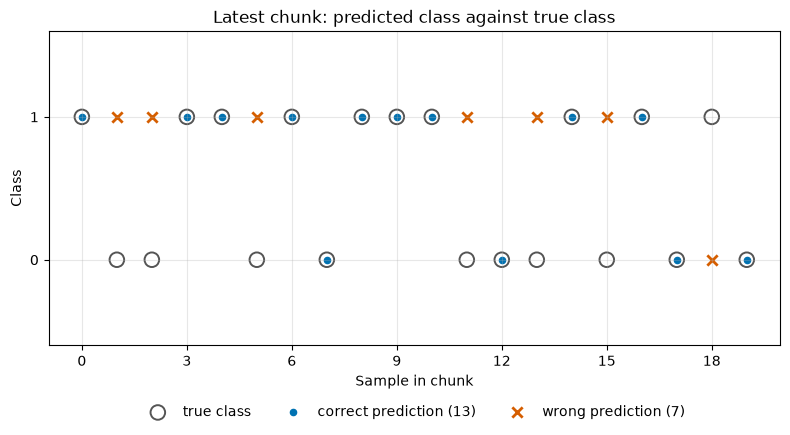

In [12]:
fig = plot_predictions_vs_ground_truth(trainer.last_true_, trainer.last_pred_,
                                       title="Latest chunk: predicted class against true class")
plt.show()

# Summary table

In [13]:
print("buffer_size  retrains  scored chunks  accuracy  ms per retrain  peak memory (KB)")
for size, t in ((50, small), (100, trainer), (200, large)):
    retrained = t.history("retrained")
    ms = 1000 * t.history("fit_seconds")[retrained].mean()
    print(f"{size:11d}  {int(retrained.sum()):8d}  {int(t.history('scored').sum()):13d}  "
          f"{t.accuracy_.result():8.3f}  {ms:14.2f}  {t.history('memory_bytes').max() / 1024:16.1f}")

buffer_size  retrains  scored chunks  accuracy  ms per retrain  peak memory (KB)
         50        10             20     0.671           24.77               6.3
        100         5             18     0.739           37.47              10.2
        200         2             14     0.751           50.70              20.6


# Take away


## What this shows

- **Streaming I/O and preprocessing:** the CSV (with missing values) is read once, then cut into chunks. The imputer and scaler update their statistics chunk by chunk.
- **Buffered retraining:** the tree stores chunks in a buffer and retrains only when the buffer is full. In between, it predicts with the last tree, and the first chunks cannot be scored at all.
- **Test, then train:** the log, the metrics and the plots all come from the same `StreamTrainer`.
- **Buffer size trade-off:** a larger buffer is more accurate but waits longer for its first tree and holds more memory. The full benchmark is in `benchmark/results/buffer_size.md`.